# Lab 5: Neural Networks (LSTM and GRU) for JPM

**Owner:** Member 5 · **Marking items covered:** 4. Modelling quality (Advanced items 1 and 2), 2. Honest validation

**The question this notebook answers:** Do LSTM or GRU networks trained on windows of our features beat the naive forecast, and are their results stable across seeds?

**Run time:** about 25 to 40 minutes on a laptop CPU. Close other programs first: TensorFlow needs a lot of memory.

## Step 1: Set up

In [17]:
NOTEBOOK_START = __import__('time').time()      # used in Step 12 to report the total CPU run time
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslab import config
from tslab.data import load_market_data
from tslab.team import build_features_jpm, make_dataset_jpm, FEATURE_GROUPS_JPM, ALL_FEATURES_JPM   # OUR features
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import (compare_models, diebold_mariano, dm_verdict, directional_accuracy,
                           directional_accuracy_test, out_of_sample_r2, rmse, mae,
                           simple_backtest, backtest_summary)
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts
from sklearn.preprocessing import StandardScaler
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import keras
from keras import layers
from tslab.nnutils import (set_seed, make_windows, build_lstm, build_gru, build_cnn,
                           fit_with_early_stopping, predict_returns)
from tslab.plots import plot_learning_curves

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(config.SEED)
print("Target stock:", config.TARGET_TICKER)

Target stock: JPM


## Step 2: The data and the walk-forward folds

Every notebook in our project uses these lines, so that every model is scored on the same days.

In [18]:
frame = load_market_data()                                              # one row per JPM trading day
dataset_all = make_dataset_jpm(frame, horizon=1)                        # includes the last row (no target yet)
latest_row = dataset_all.iloc[[-1]]                                     # kept aside for a real forecast
dataset = dataset_all.dropna(subset=["target_return"])
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

print("Rows in the modelling table:", len(dataset))                     # expect 2789
print("Walk-forward folds         :", len(splits))                      # expect 29
print("First test day:", dataset.index[splits[0][1][0]].date(), "| last test day:", dataset.index[splits[-1][1][-1]].date())

Loaded 2989 trading days of JPM, 2015-01-02 to 2026-11-19, with 8 predictor series.
Rows in the modelling table: 2789
Walk-forward folds         : 29
First test day: 2019-10-08 | last test day: 2026-11-18


## Step 3: Settings and features

Close other programs first (TensorFlow needs memory). Our feature list = Notebook 6's list plus the financial sector.

In [19]:
WINDOW = 20
MAX_EPOCHS = 60
NN_TEST_SIZE = 252
VALIDATION_SHARE = 0.15          # validation = the LAST 15% of each training block
PATIENCE = 8                     # early stopping: stop after 8 epochs without a better validation loss
SEEDS = [42, 7, 2024]            # the three seeds for the stability test (Step 9)

NN_FEATURES = [
    "ret_lag1", "ret_21d", "vol_5d", "vol_21d", "range_hl",
    "rsi_14", "macd_hist", "bb_percent_b", "dist_sma_50",
    "gap_overnight", "move_intraday", "volume_rel_20d",
    "SP500_ret_1d", "TECH_ret_1d", "GOLD_ret_1d", "BRENT_ret_1d", "USD_ret_1d",
    "VIX_level", "VIX_change_1d", "US10Y_change_5d",
    "FIN_ret_1d", "relative_to_FIN_5d",           # added by our group
]
features = dataset[NN_FEATURES].values
target = dataset["target_return"].values
print("Features per day:", len(NN_FEATURES), "| rows:", len(dataset))

Features per day: 22 | rows: 2789


## Step 4: The rules we follow

Every network in this notebook follows the same four rules. Each one closes a door through which information from the future could leak into the model.

1. **Scalers are fitted on the training rows only.** The mean and standard deviation of each feature, and the standard deviation used to scale the target, are computed from the rows the network trains on. They are then applied unchanged to the validation and test rows. The future's averages are future information.
2. **Validation data comes from the end of the training block** (the last 15%), never picked at random. A random pick would put days from *after* some training days into validation, and the network would be checked on a period it has partly seen around.
3. **Early stopping on the validation loss.** Training stops when the validation loss has not improved for 8 epochs, and the weights from the best epoch are kept. This stops the network memorising the noise in the training days.
4. **A fixed seed before every model** (`set_seed`). Networks start from random weights, so without a seed two runs of the same cell give different answers and nobody could repeat our result.

Two more: the test block is never used to choose any setting (tuning uses the first block's validation data only, Step 7), and a new network is built for every fold, so no model is carried from one fold into the next.

## Step 5: The tempting mistake

Many tutorials train a network on the **price** itself. We repeat that (Notebook 6, Step 3) to show why we do not: the price is scaled to 0 to 1 using the training days, cut into 20-day windows, and an LSTM learns the next day's scaled price. The last 20% of days are the test.

Training windows: 2371 | test windows: 598
Largest scaled price in the TRAINING period: 1.00
Largest scaled price in the TEST period    : 2.04   (above 1 = prices the network never saw)
Trained in 19 seconds
LSTM on the price:  RMSE = $39.11
Naive forecast   :  RMSE = $4.17


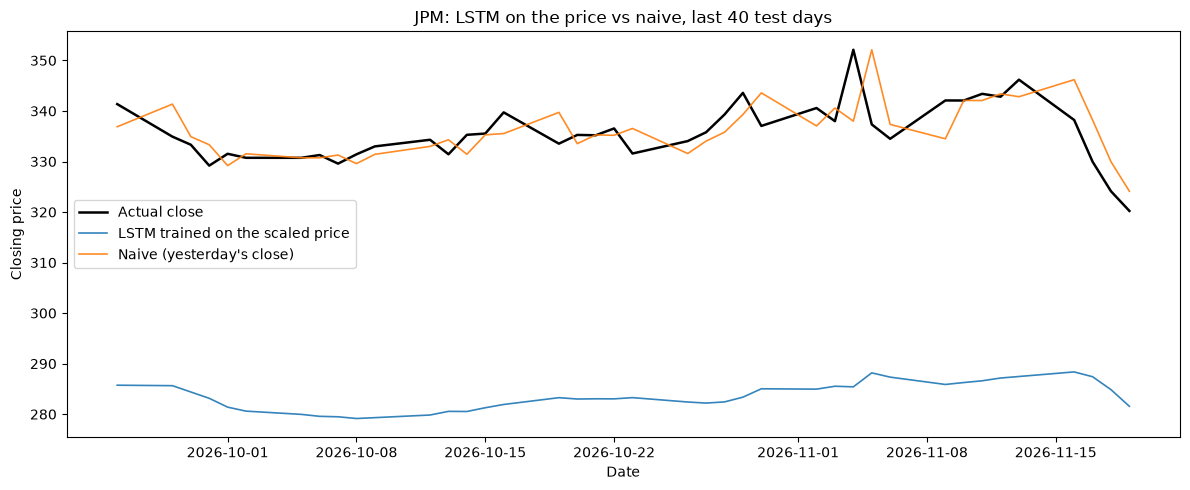

In [20]:
from sklearn.preprocessing import MinMaxScaler

prices = frame["Close"].values.reshape(-1, 1)
split = int(len(prices) * 0.8)

price_scaler = MinMaxScaler().fit(prices[:split])           # fitted on the training days only
scaled = price_scaler.transform(prices)

X_p, y_p = make_windows(scaled[:-1], scaled[1:, 0], WINDOW)  # label = scaled price on the next day
window_end_p = np.arange(WINDOW - 1, len(prices) - 1)
is_train_p = window_end_p + 1 < split

print("Training windows:", is_train_p.sum(), "| test windows:", (~is_train_p).sum())
print(f"Largest scaled price in the TRAINING period: {scaled[:split].max():.2f}")
print(f"Largest scaled price in the TEST period    : {scaled[split:].max():.2f}   (above 1 = prices the network never saw)")

set_seed(config.SEED)
keras.backend.clear_session()
price_model = build_lstm(WINDOW, 1, units=32)
started = time.time()
price_model.fit(X_p[is_train_p], y_p[is_train_p], epochs=30, batch_size=32,
                validation_split=0.1, shuffle=False, verbose=0)
print(f"Trained in {time.time() - started:.0f} seconds")

predicted_price = price_scaler.inverse_transform(price_model.predict(X_p[~is_train_p], verbose=0).reshape(-1, 1)).ravel()
actual_price = price_scaler.inverse_transform(y_p[~is_train_p].reshape(-1, 1)).ravel()
yesterday_price = price_scaler.inverse_transform(X_p[~is_train_p][:, -1, 0].reshape(-1, 1)).ravel()   # naive

print(f"LSTM on the price:  RMSE = ${rmse(actual_price, predicted_price):.2f}")
print(f"Naive forecast   :  RMSE = ${rmse(actual_price, yesterday_price):.2f}")

test_dates_p = frame.index[window_end_p[~is_train_p] + 1]
plot_price_forecasts(test_dates_p, actual_price,
                     {"LSTM trained on the scaled price": predicted_price, "Naive (yesterday's close)": yesterday_price},
                     title="JPM: LSTM on the price vs naive, last 40 test days", last_n=40)

**What this shows.** The LSTM trained on the price looks good on the full chart because its line follows JPM's price, but its test RMSE is **USD39.11** against **USD4.17** for simply using yesterday's close, almost ten times worse. JPM rose far above anything in the training period (the scaled test price reaches 2.04, while the network only ever saw values up to 1.00), so the network keeps predicting prices from a range it knows and lags far behind. This is why everything below forecasts **returns**, not prices.

## Step 6: One fold with the predict-zero line

First the walk-forward function (copied from Notebook 6, Step 6, with the window as a setting so that Step 7's tuned window can be used). For every fold it: splits the training block in time (first 85% to fit, last 15% to validate); fits the scaler on the 85% only; builds windows; trains with early stopping; predicts the test block; and throws the model away.

Predicting a return of **zero** is the naive forecast ("tomorrow's price = today's"). Because the target is scaled by its standard deviation, the validation loss of predicting zero is about 1. **If a network's best validation loss is not lower than the predict-zero loss, it has learned nothing useful.**

In [21]:
def walk_forward_nn(architecture, seed=config.SEED, window=WINDOW, max_folds=None, verbose=True, **model_options):
    """Walk-forward test of one network. Returns (predicted next-day returns, per-fold details)."""
    predictions = pd.Series(np.nan, index=dataset.index, name=architecture)
    details = []
    fold_starts = list(range(config.INITIAL_TRAIN, len(dataset), NN_TEST_SIZE))
    if max_folds:
        fold_starts = fold_starts[:max_folds]
    builder = {"LSTM": build_lstm, "GRU": build_gru, "CNN": build_cnn}[architecture]

    for fold, train_end in enumerate(fold_starts, start=1):
        started = time.time()
        test_end = min(train_end + NN_TEST_SIZE, len(dataset))
        fit_end = int(train_end * (1 - VALIDATION_SHARE))       # [0, fit_end) fit, [fit_end, train_end) validate

        scaler = StandardScaler().fit(features[:fit_end])        # fitting rows ONLY
        features_scaled = scaler.transform(features[:test_end])
        target_scale = target[:fit_end].std()
        target_scaled = target[:test_end] / target_scale

        X_all, y_all = make_windows(features_scaled, target_scaled, window)
        window_end = np.arange(window - 1, test_end)
        in_fit = window_end < fit_end
        in_val = (window_end >= fit_end) & (window_end < train_end)
        in_test = window_end >= train_end

        set_seed(seed)
        keras.backend.clear_session()
        model = builder(window, len(NN_FEATURES), **model_options)
        history = fit_with_early_stopping(model, X_all[in_fit], y_all[in_fit], X_all[in_val], y_all[in_val],
                                          epochs=MAX_EPOCHS, batch_size=64, patience=PATIENCE)

        predictions.iloc[window_end[in_test]] = predict_returns(model, X_all[in_test]) * target_scale
        details.append({"fold": fold,
                        "train_rows": train_end,
                        "test_from": dataset.index[train_end].date(),
                        "test_to": dataset.index[test_end - 1].date(),
                        "epochs_run": len(history.history["loss"]),
                        "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
                        "best_val_loss": float(min(history.history["val_loss"])),
                        "zero_val_loss": float(np.mean(y_all[in_val] ** 2)),
                        "seconds": time.time() - started})
        if verbose:
            d = details[-1]
            print(f"  {architecture} fold {fold}/{len(fold_starts)}: best epoch {d['best_epoch']:>2}, "
                  f"val loss {d['best_val_loss']:.3f} vs zero {d['zero_val_loss']:.3f}, {d['seconds']:.0f} s")
    details = pd.DataFrame(details)
    details["beats_zero_on_validation"] = details["best_val_loss"] < details["zero_val_loss"]
    return predictions, details

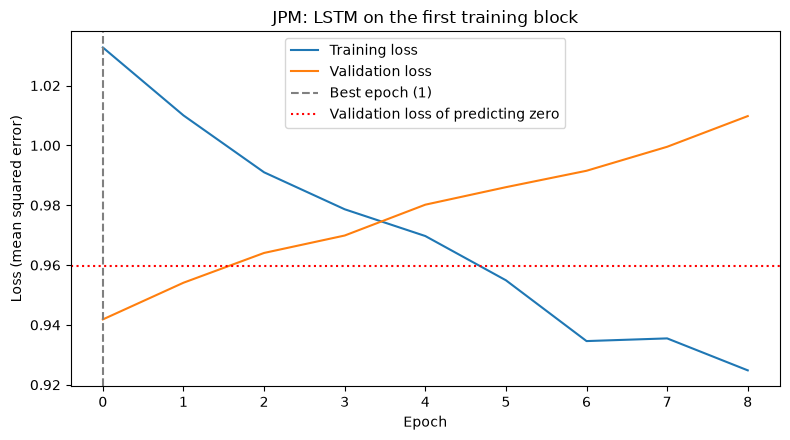

Validation loss of always predicting zero (naive): 0.960
Lowest validation loss reached by the LSTM       : 0.942  (epoch 1)
Parameters: 7585 | training windows: 831
Learned something useful? YES


In [22]:
# One fold, on the first training block only (rows 0 to 999): an LSTM with the default settings
train_end = config.INITIAL_TRAIN
fit_end = int(train_end * (1 - VALIDATION_SHARE))
scaler = StandardScaler().fit(features[:fit_end])
f_scaled = scaler.transform(features[:train_end])
t_scale = target[:fit_end].std()
X_f, y_f = make_windows(f_scaled, target[:train_end] / t_scale, WINDOW)
ends = np.arange(WINDOW - 1, train_end)

set_seed(config.SEED)
keras.backend.clear_session()
model = build_lstm(WINDOW, len(NN_FEATURES), units=32)
history = fit_with_early_stopping(model, X_f[ends < fit_end], y_f[ends < fit_end],
                                  X_f[ends >= fit_end], y_f[ends >= fit_end], epochs=MAX_EPOCHS, patience=PATIENCE)
zero_loss = float(np.mean(y_f[ends >= fit_end] ** 2))
best_loss = min(history.history["val_loss"])
plot_learning_curves(history, "JPM: LSTM on the first training block", reference=zero_loss)

print(f"Validation loss of always predicting zero (naive): {zero_loss:.3f}")
print(f"Lowest validation loss reached by the LSTM       : {best_loss:.3f}  (epoch {int(np.argmin(history.history['val_loss'])) + 1})")
print("Parameters:", model.count_params(), "| training windows:", int((ends < fit_end).sum()))
print("Learned something useful?", "YES" if best_loss < zero_loss else "NO: it did not beat predicting zero")

**What this shows.** On the first block the LSTM's best validation loss (**0.942**) is only slightly below the loss of predicting zero (**0.960**), and it got there at **epoch 1**, before it had learned much: a freshly started network outputs numbers close to zero, which is almost the naive forecast. After that, the training loss keeps falling while the validation loss rises, so the network is fitting noise; early stopping returns the epoch-1 weights. With 7,585 weights and only 831 training windows, a gap this small is not evidence of skill. The walk-forward test in Step 8 is the real test.

## Step 7: Tuning on validation data only

We tune the GRU on the **first training block's validation data only** (rows 850 to 999, all before the first test day of 8 October 2019). Three settings: window 10, 20, 40 × units 16, 32 × dropout 0.1, 0.3 = 12 runs. The test period is never looked at. The winning settings are then used for every fold of the real test, for both the LSTM and the GRU.

The predict-zero loss depends on the window (a longer window loses a few early rows), so it is shown on every row.

In [23]:
first_train_end = config.INITIAL_TRAIN
first_fit_end = int(first_train_end * (1 - VALIDATION_SHARE))

def validation_loss_for(window, units, dropout, seed=config.SEED):
    scaler = StandardScaler().fit(features[:first_fit_end])               # fitting rows only
    f_scaled = scaler.transform(features[:first_train_end])
    scale = target[:first_fit_end].std()
    X_w, y_w = make_windows(f_scaled, target[:first_train_end] / scale, window)
    ends = np.arange(window - 1, first_train_end)
    fit, val = ends < first_fit_end, ends >= first_fit_end
    set_seed(seed); keras.backend.clear_session()
    m = build_gru(window, len(NN_FEATURES), units=units, dropout=dropout)
    h = fit_with_early_stopping(m, X_w[fit], y_w[fit], X_w[val], y_w[val], epochs=MAX_EPOCHS, patience=PATIENCE)
    return {"best_val_loss": float(min(h.history["val_loss"])), "zero_val_loss": float(np.mean(y_w[val] ** 2)),
            "best_epoch": int(np.argmin(h.history["val_loss"])) + 1}

started = time.time()
rows = []
for window in (10, 20, 40):
    for units in (16, 32):
        for dropout in (0.1, 0.3):
            rows.append({"window": window, "units": units, "dropout": dropout, **validation_loss_for(window, units, dropout)})
tuning = pd.DataFrame(rows)
tuning["beats_zero"] = tuning["best_val_loss"] < tuning["zero_val_loss"]
tuning = tuning.sort_values("best_val_loss").reset_index(drop=True)
print(f"12 tuning runs in {time.time() - started:.0f} seconds")

os.makedirs(config.OUTPUT_DIR, exist_ok=True)
tuning.to_csv(config.OUTPUT_DIR / "nn_tuning.csv", index=False)
print("Saved outputs/nn_tuning.csv")
display(tuning.round(4))

best = tuning.iloc[0]
BEST_WINDOW, BEST_UNITS, BEST_DROPOUT = int(best["window"]), int(best["units"]), float(best["dropout"])
print(f"Chosen on validation data: window {BEST_WINDOW}, units {BEST_UNITS}, dropout {BEST_DROPOUT}")
print(f"Settings whose validation loss is below predicting zero: {int(tuning['beats_zero'].sum())} of {len(tuning)}")

12 tuning runs in 101 seconds
Saved outputs/nn_tuning.csv


,window,units,dropout,best_val_loss,zero_val_loss,best_epoch,beats_zero
0,20,32,0.3,0.9517,0.9596,4,True
1,20,32,0.1,0.9578,0.9596,4,True
2,40,32,0.1,0.9640,0.9596,4,False
3,40,16,0.3,0.9656,0.9596,14,False
4,40,32,0.3,0.9684,0.9596,6,False
5,10,32,0.1,0.9691,0.9596,4,False
6,10,32,0.3,0.9704,0.9596,7,False
7,40,16,0.1,0.9763,0.9596,9,False
8,10,16,0.1,0.9790,0.9596,2,False
9,10,16,0.3,0.9814,0.9596,7,False


Chosen on validation data: window 20, units 32, dropout 0.3
Settings whose validation loss is below predicting zero: 2 of 12


**What this shows.** The winning setting is **window 20, 32 units, dropout 0.3** (validation loss 0.952). Only **2 of the 12** settings get below the predict-zero loss of 0.960, and only just: the best one is 0.8% lower. The other 10 are worse than predicting zero. So tuning mainly found the "least bad" network, not a good one, and choosing the best of 12 noisy runs flatters the winner a little. These settings were fixed here, before any test day was looked at.

## Step 8: Walk-forward test of LSTM and GRU

Both architectures use the settings chosen in Step 7. Networks are slow, so each test block is one year (252 rows) instead of one quarter: the first network trains on rows 0 to 999 and predicts rows 1000 to 1251, the next trains on 0 to 1251, and so on. The test days are the same 8 October 2019 to 18 November 2026 as every other member's.

In [24]:
nn_predictions = {}
nn_details = {}
LABEL = f"w{BEST_WINDOW} u{BEST_UNITS} d{BEST_DROPOUT}"
started = time.time()
for architecture in ["LSTM", "GRU"]:
    series, details = walk_forward_nn(architecture, seed=config.SEED, window=BEST_WINDOW,
                                      units=BEST_UNITS, dropout=BEST_DROPOUT)
    nn_predictions[f"{architecture} {LABEL}"] = series
    nn_details[architecture] = details
print(f"LSTM and GRU walk-forward finished in {(time.time() - started) / 60:.1f} minutes")

  LSTM fold 1/8: best epoch  1, val loss 0.940 vs zero 0.960, 6 s
  LSTM fold 2/8: best epoch 32, val loss 7.915 vs zero 8.085, 13 s
  LSTM fold 3/8: best epoch  7, val loss 0.552 vs zero 0.552, 8 s
  LSTM fold 4/8: best epoch  4, val loss 0.953 vs zero 0.928, 7 s
  LSTM fold 5/8: best epoch  3, val loss 0.698 vs zero 0.688, 6 s
  LSTM fold 6/8: best epoch  7, val loss 0.431 vs zero 0.421, 8 s
  LSTM fold 7/8: best epoch  6, val loss 0.819 vs zero 0.823, 7 s
  LSTM fold 8/8: best epoch  6, val loss 0.767 vs zero 0.753, 9 s
  GRU fold 1/8: best epoch  4, val loss 0.952 vs zero 0.960, 7 s
  GRU fold 2/8: best epoch  9, val loss 8.134 vs zero 8.085, 8 s
  GRU fold 3/8: best epoch  3, val loss 0.550 vs zero 0.552, 9 s
  GRU fold 4/8: best epoch  9, val loss 0.983 vs zero 0.928, 8 s
  GRU fold 5/8: best epoch  3, val loss 0.699 vs zero 0.688, 6 s
  GRU fold 6/8: best epoch  2, val loss 0.406 vs zero 0.421, 7 s
  GRU fold 7/8: best epoch  1, val loss 0.827 vs zero 0.823, 8 s
  GRU fold 8/8: 

In [25]:
for architecture, details in nn_details.items():
    print(f"\n{architecture} {LABEL}, one row per fold:")
    display(details.drop(columns="seconds").round(3))
    print(f"Folds where validation loss beat predicting zero: {int(details['beats_zero_on_validation'].sum())} of {len(details)}")


LSTM w20 u32 d0.3, one row per fold:


,fold,train_rows,test_from,test_to,epochs_run,best_epoch,best_val_loss,zero_val_loss,beats_zero_on_validation
0,1,1000,2019-10-08,2020-10-06,9,1,0.940,0.960,True
1,2,1252,2020-10-07,2021-10-06,40,32,7.915,8.085,True
2,3,1504,2021-10-07,2022-10-06,15,7,0.552,0.552,True
3,4,1756,2022-10-07,2023-10-09,12,4,0.953,0.928,False
4,5,2008,2023-10-10,2024-10-09,11,3,0.698,0.688,False
5,6,2260,2024-10-10,2025-10-13,15,7,0.431,0.421,False
6,7,2512,2025-10-14,2026-10-14,14,6,0.819,0.823,True
7,8,2764,2026-10-15,2026-11-18,14,6,0.767,0.753,False


Folds where validation loss beat predicting zero: 4 of 8

GRU w20 u32 d0.3, one row per fold:


,fold,train_rows,test_from,test_to,epochs_run,best_epoch,best_val_loss,zero_val_loss,beats_zero_on_validation
0,1,1000,2019-10-08,2020-10-06,12,4,0.952,0.960,True
1,2,1252,2020-10-07,2021-10-06,17,9,8.134,8.085,False
2,3,1504,2021-10-07,2022-10-06,11,3,0.550,0.552,True
3,4,1756,2022-10-07,2023-10-09,17,9,0.983,0.928,False
4,5,2008,2023-10-10,2024-10-09,11,3,0.699,0.688,False
5,6,2260,2024-10-10,2025-10-13,10,2,0.406,0.421,True
6,7,2512,2025-10-14,2026-10-14,9,1,0.827,0.823,False
7,8,2764,2026-10-15,2026-11-18,16,8,0.763,0.753,False


Folds where validation loss beat predicting zero: 3 of 8


## Step 9: Three seeds

The GRU with the tuned settings is our "best network", chosen **before** looking at any test result (it is the architecture that was tuned). We run the full walk-forward with seeds 42, 7 and 2024. Seed 42 is the run from Step 8. We also average the three runs' predictions (an ensemble), which is the honest way to use several seeds; picking the luckiest seed would be tuning on the test period.

In [26]:
best_name = f"GRU {LABEL}"
seed_runs = {42: nn_predictions[best_name]}
started = time.time()
for seed in [s for s in SEEDS if s != 42]:
    seed_runs[seed], _ = walk_forward_nn("GRU", seed=seed, window=BEST_WINDOW, units=BEST_UNITS,
                                         dropout=BEST_DROPOUT, verbose=False)
    print(f"  seed {seed} done")
print(f"Extra seeds finished in {(time.time() - started) / 60:.1f} minutes")

mask = pd.concat(seed_runs, axis=1).notna().all(axis=1)
actual_ret = dataset.loc[mask, "target_return"]
close_today = dataset.loc[mask, "close"]
actual_close = dataset.loc[mask, "target_close"]

def score(pred):
    return {"rmse_price": rmse(actual_close, close_today * np.exp(pred)),
            "r2_oos": out_of_sample_r2(actual_ret, pred),
            "directional_accuracy": directional_accuracy(actual_ret, pred)}

rows = [{"run": "Naive (no change)", "seed": "", "rmse_price": rmse(actual_close, close_today),
         "r2_oos": 0.0, "directional_accuracy": np.nan}]
for seed, series in seed_runs.items():
    rows.append({"run": best_name, "seed": seed, **score(series[mask])})
per_seed = pd.DataFrame(rows[1:])
rows.append({"run": "Average of the 3 seeds' scores", "seed": "mean",
             **per_seed[["rmse_price", "r2_oos", "directional_accuracy"]].mean().to_dict()})
ensemble = pd.concat(seed_runs, axis=1).mean(axis=1, skipna=False)
rows.append({"run": f"{best_name} (3-seed average forecast)", "seed": "ensemble", **score(ensemble[mask])})
seed_table = pd.DataFrame(rows)
seed_table.to_csv(config.OUTPUT_DIR / "nn_seeds.csv", index=False)
print("Saved outputs/nn_seeds.csv  | test days scored:", int(mask.sum()))
display(seed_table.round(5))

r2_spread = per_seed["r2_oos"].max() - per_seed["r2_oos"].min()
r2_gap = abs(per_seed["r2_oos"].mean())
print(f"Spread of R2 across seeds: {r2_spread:.4f}   |   average R2 distance from naive (0): {r2_gap:.4f}")
print("The seeds disagree MORE than the model differs from naive: any 'skill' is noise." if r2_spread > r2_gap
      else "The seeds agree more closely than the gap to naive.")
nn_predictions[f"{best_name} (3-seed average)"] = ensemble

  seed 7 done
  seed 2024 done
Extra seeds finished in 2.5 minutes
Saved outputs/nn_seeds.csv  | test days scored: 1789


,run,seed,rmse_price,r2_oos,directional_accuracy
0,Naive (no change),,2.97367,0.00000,NaN
1,GRU w20 u32 d0.3,42,3.00851,-0.01888,0.52376
2,GRU w20 u32 d0.3,7,3.01373,-0.01925,0.49581
3,GRU w20 u32 d0.3,2024,3.00140,-0.02124,0.51873
4,Average of the 3 seeds' scores,mean,3.00788,-0.01979,0.51276
5,GRU w20 u32 d0.3 (3-seed average forecast),ensemble,2.97919,-0.00528,0.51369


Spread of R2 across seeds: 0.0024   |   average R2 distance from naive (0): 0.0198
The seeds agree more closely than the gap to naive.


**What this shows.** All three seeds give an RMSE of about **USD3.00 to USD3.01** (naive: **USD2.97**) and an R² of **−0.019 to −0.021**. The spread across seeds (0.0024) is smaller than the average distance from naive (0.020), so the seeds agree with each other, and what they agree on is that the GRU is **slightly worse than naive** every time. Directional accuracy moves more: 52.4%, 49.6% and 51.9%, so whether the GRU calls up and down days "better than a coin" depends on the seed. Averaging the three forecasts (R² −0.005, RMSE USD2.98) is steadier than any single seed, but it still does not beat naive.

## Step 10: Compare with naive

All networks next to the naive forecast, and next to Member 2's ARMAX and Member 3's Ridge and gradient boosting, scored on **exactly the same days**. The Diebold-Mariano (DM) test asks whether each model's squared errors differ from naive's by more than luck. A negative statistic means the model has smaller errors; it only "beats naive" if the statistic is negative **and** p < 0.05.

In [27]:
all_predictions = dict(nn_predictions)
for file_name, wanted in [("predictions_classical.csv", ["ARMAX"]), ("predictions_ml.csv", ["Ridge", "Gradient boosting"])]:
    file = config.OUTPUT_DIR / file_name
    if file.exists():
        saved = pd.read_csv(file, index_col=0, parse_dates=True)
        for name in wanted:
            if name in saved.columns:
                all_predictions[name] = saved[name].reindex(dataset.index)
    else:
        print(f"Note: {file_name} not found (Members 2 and 3's files), so those models are left out.")

scores = compare_models(dataset, all_predictions)          # adds 'Naive (no change)' itself, same rows for all
display(scores.round(4))

scored_rows = pd.concat(all_predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]
print("Rows scored:", len(scored_rows), "| from", scored_rows[0].date(), "to", scored_rows[-1].date())

rows = [{"Model": "Naive (no change)", "DM statistic vs naive": np.nan, "DM p-value": np.nan,
         "Verdict": "baseline", "Beats naive?": "baseline", "Hit rate": np.nan, "Hit rate p-value": np.nan}]
for name, series in all_predictions.items():
    stat, p_dm = diebold_mariano(actual, series.loc[scored_rows], np.zeros(len(scored_rows)))
    hit, p_dir = directional_accuracy_test(actual, series.loc[scored_rows])
    rows.append({"Model": name, "DM statistic vs naive": stat, "DM p-value": p_dm, "Verdict": dm_verdict(stat, p_dm),
                 "Beats naive?": "Yes" if (stat < 0 and p_dm < 0.05) else "No", "Hit rate": hit, "Hit rate p-value": p_dir})
dm_table = pd.DataFrame(rows).set_index("Model")
display(dm_table.round(4))

,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),2.9737,2.0128,1.2504,NaN,0.0000
LSTM w20 u32 d0.3,3.0232,2.0516,1.2739,0.4925,-0.0327
GRU w20 u32 d0.3,3.0085,2.0241,1.2598,0.5238,-0.0189
GRU w20 u32 d0.3 (3-seed average),2.9792,2.0225,1.2567,0.5137,-0.0053
ARMAX,3.0005,2.0294,1.2635,0.5271,-0.0145
Ridge,2.9725,2.0066,1.2484,0.5355,0.0005
Gradient boosting,2.9958,2.0223,1.2591,0.5266,-0.0180


Rows scored: 1789 | from 2019-10-08 to 2026-11-18


,DM statistic vs naive,DM p-value,Verdict,Beats naive?,Hit rate,Hit rate p-value
Model,,,,,,
Naive (no change),NaN,NaN,baseline,baseline,NaN,NaN
LSTM w20 u32 d0.3,3.7681,0.0002,Significantly WORSE than naive,No,0.4925,0.5388
GRU w20 u32 d0.3,1.3273,0.1846,No significant difference,No,0.5238,0.0470
GRU w20 u32 d0.3 (3-seed average),0.5964,0.5510,No significant difference,No,0.5137,0.2564
ARMAX,1.0358,0.3004,No significant difference,No,0.5271,0.0232
Ridge,-0.2353,0.8140,No significant difference,No,0.5355,0.0029
Gradient boosting,1.7619,0.0783,No significant difference,No,0.5266,0.0262


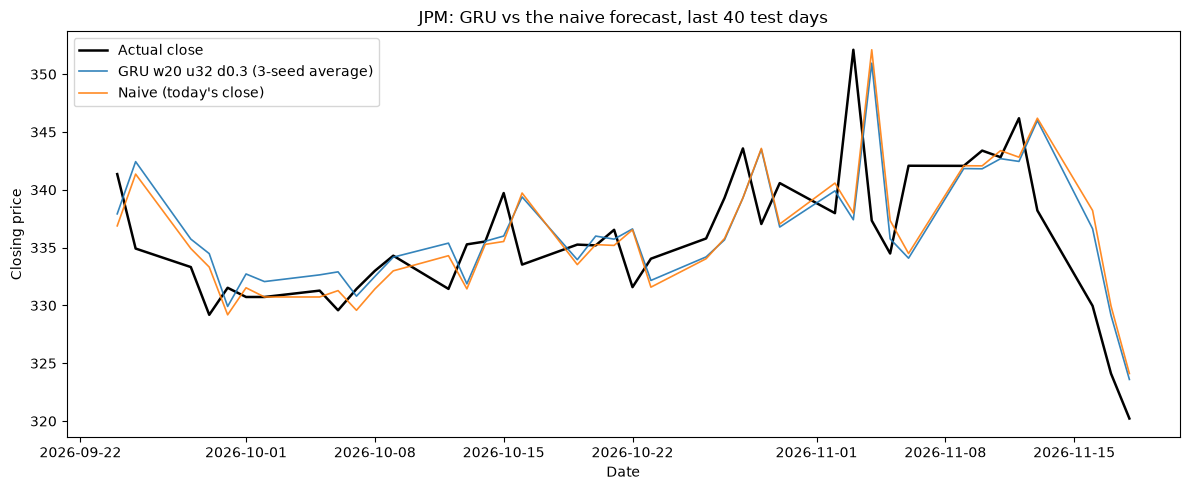

In [28]:
# Price view of the 3-seed GRU against naive for the last 40 scored days
scored = dataset.loc[scored_rows]
plot_price_forecasts(
    scored.index, scored["target_close"].values,
    {f"{best_name} (3-seed average)": (scored["close"] * np.exp(ensemble.loc[scored_rows])).values,
     "Naive (today's close)": scored["close"].values},
    title="JPM: GRU vs the naive forecast, last 40 test days", last_n=40)

In [29]:
# Save (the file Member 6 reads). One column per network setting, predicted next-day log return, NaN on training days.
pd.concat(nn_predictions, axis=1).rename_axis("Date").to_csv(config.OUTPUT_DIR / "predictions_nn.csv")
print("Saved outputs/predictions_nn.csv with columns:", list(nn_predictions))

Saved outputs/predictions_nn.csv with columns: ['LSTM w20 u32 d0.3', 'GRU w20 u32 d0.3', 'GRU w20 u32 d0.3 (3-seed average)']


## Step 11: 63-day path from a multi-output GRU

One GRU with **63 outputs**: output *h* is the log return from today's close to the close *h* trading days later (h = 1 to 63). It reads the last window of our features and produces the whole path at once.

Two runs, both following the rules of Step 4:

1. **A hold-out check.** Train on everything except the last 252 forecast origins and test on those 252 days. Training labels stop 63 days before the first test day, so no training label overlaps the test period. We compare with the **flat line** (predict zero return at every horizon = the naive forecast).
2. **The final path.** Retrain on all history and forecast the 63 trading days after 19 November 2026, on the same dates as Member 4's `forecast_basic.csv`.

In [30]:
H = 63
path_features = dataset_all[NN_FEATURES].values                 # includes 19 Nov 2026 (the forecast origin)
closes = dataset_all["close"].values
n_rows = len(dataset_all)
n_labeled = n_rows - H                                          # rows whose full 63-day future is known
cum_returns = np.column_stack([np.log(closes[h:h + n_labeled] / closes[:n_labeled]) for h in range(1, H + 1)])

def build_path_gru(window, n_features, units, dropout, outputs=H):
    model = keras.Sequential([layers.Input(shape=(window, n_features)),
                              layers.GRU(units, kernel_regularizer=keras.regularizers.l2(1e-4)),
                              layers.Dropout(dropout),
                              layers.Dense(32, activation="relu"),
                              layers.Dense(outputs)])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model

def fit_path_model(label_end, seed=config.SEED):
    """Train on origins [0, label_end). Validation = last 15% of them; a 63-row gap stops label overlap."""
    val_start = int(label_end * (1 - VALIDATION_SHARE))
    fit_end = val_start - H                                     # fit labels end before validation days begin
    scaler = StandardScaler().fit(path_features[:fit_end])
    scales = cum_returns[:fit_end].std(axis=0)                  # one scale per horizon, fitting rows only
    X_all, _ = make_windows(scaler.transform(path_features), np.zeros(n_rows), BEST_WINDOW)
    ends = np.arange(BEST_WINDOW - 1, n_rows)                   # X_all[k] is the window ending on row ends[k]
    fit = ends < fit_end
    val = (ends >= val_start) & (ends < label_end)
    y_fit, y_val = cum_returns[ends[fit]] / scales, cum_returns[ends[val]] / scales
    set_seed(seed); keras.backend.clear_session()
    m = build_path_gru(BEST_WINDOW, len(NN_FEATURES), BEST_UNITS, BEST_DROPOUT)
    hist = fit_with_early_stopping(m, X_all[fit], y_fit, X_all[val], y_val, epochs=MAX_EPOCHS, patience=PATIENCE)
    info = {"best_val_loss": float(min(hist.history["val_loss"])), "zero_val_loss": float(np.mean(y_val ** 2)),
            "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1}
    return m, X_all, ends, scales, info

# 1. Hold-out check on the last 252 forecast origins
test_start = n_labeled - 252
started = time.time()
m_check, X_all, ends, scales, info = fit_path_model(test_start - H)    # no training label reaches into the test days
test_idx = (ends >= test_start) & (ends < n_labeled)
pred_test = np.asarray(m_check(X_all[test_idx], training=False)) * scales
true_test = cum_returns[ends[test_idx]]
print(f"Hold-out model trained in {time.time() - started:.0f} s | validation loss {info['best_val_loss']:.3f} "
      f"vs predicting zero {info['zero_val_loss']:.3f}")
print("Test origins:", dataset_all.index[test_start].date(), "to", dataset_all.index[n_labeled - 1].date())

check_rows = []
for h in [1, 5, 21, 63]:
    a, p = true_test[:, h - 1], pred_test[:, h - 1]
    stat, p_dm = diebold_mariano(a, p, np.zeros(len(a)), horizon=h)
    check_rows.append({"horizon_days": h, "rmse_gru": rmse(a, p), "rmse_flat_line": rmse(a, np.zeros(len(a))),
                       "r2_oos": out_of_sample_r2(a, p), "direction_right": directional_accuracy(a, p),
                       "dm_stat": stat, "dm_p": p_dm, "beats_flat_line": "Yes" if (stat < 0 and p_dm < 0.05) else "No",
                       "independent_periods": len(a) // h})
path_check = pd.DataFrame(check_rows)
display(path_check.round(4))

Hold-out model trained in 9 s | validation loss 0.758 vs predicting zero 0.891
Test origins: 2025-08-21 to 2026-08-21


,horizon_days,rmse_gru,rmse_flat_line,r2_oos,direction_right,dm_stat,dm_p,beats_flat_line,independent_periods
0,1,0.0141,0.0141,0.0041,0.5079,-0.3399,0.7342,No,252
1,5,0.0274,0.0276,0.0146,0.5317,-0.4566,0.6483,No,50
2,21,0.0515,0.0542,0.0992,0.5794,-1.0041,0.3163,No,12
3,63,0.0768,0.0853,0.1883,0.6508,-0.7631,0.4461,No,4


Final model trained in 8 s | validation loss 0.706 vs predicting zero 0.774
Saved outputs/forecast_nn_path.csv | forecast made from the close of 2026-11-19 ($320.22)


,date,horizon,gru_path,naive
0,2026-11-20,1,321.09,320.22
4,2026-11-27,5,322.35,320.22
20,2026-12-21,21,328.97,320.22
41,2027-01-22,42,331.69,320.22
62,2027-02-23,63,335.41,320.22


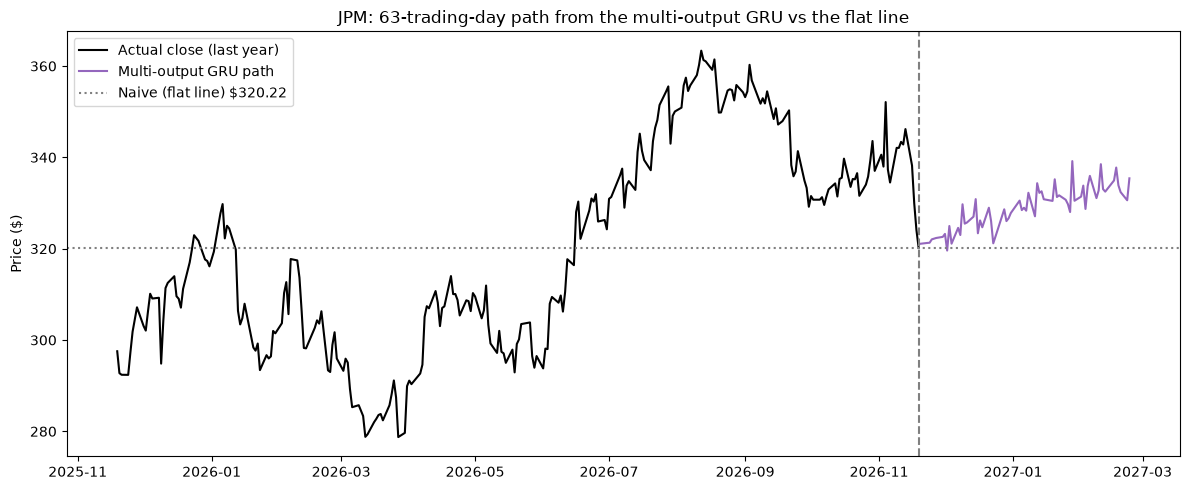

In [31]:
# 2. Final model on all known history, then the path from 19 Nov 2026
started = time.time()
m_final, X_all, ends, scales, info_final = fit_path_model(n_labeled)
path_returns = np.asarray(m_final(X_all[[-1]], training=False)).ravel() * scales    # window ending on the last row
print(f"Final model trained in {time.time() - started:.0f} s | validation loss {info_final['best_val_loss']:.3f} "
      f"vs predicting zero {info_final['zero_val_loss']:.3f}")

last_close, last_date = float(frame["Close"].iloc[-1]), frame.index[-1]
basic_file = config.DATA_DIR / "forecast_basic.csv"
if basic_file.exists():                                           # Member 4's dates, so the files line up in Power BI
    future_dates = pd.to_datetime(pd.read_csv(basic_file)["date"])
else:                                                             # same calendar as Member 4 (NYSE holidays)
    trading_day = pd.offsets.CustomBusinessDay(holidays=["2026-11-26", "2026-12-25", "2027-01-01", "2027-01-18", "2027-02-15"])
    future_dates = pd.Series(pd.date_range(last_date + trading_day, periods=H, freq=trading_day))
assert len(future_dates) == H

nn_path = pd.DataFrame({"date": future_dates.values, "horizon": np.arange(1, H + 1),
                        "gru_path": last_close * np.exp(path_returns), "naive": last_close})
nn_path.to_csv(config.OUTPUT_DIR / "forecast_nn_path.csv", index=False, date_format="%Y-%m-%d")
print(f"Saved outputs/forecast_nn_path.csv | forecast made from the close of {last_date.date()} (${last_close:.2f})")
display(nn_path.round(2).iloc[[0, 4, 20, 41, 62]])

history_close = frame["Close"].iloc[-252:]
plt.figure(figsize=(12, 5))
plt.plot(history_close, color="black", label="Actual close (last year)")
plt.plot(nn_path["date"], nn_path["gru_path"], color="tab:purple", label="Multi-output GRU path")
plt.axhline(last_close, color="grey", linestyle=":", label=f"Naive (flat line) ${last_close:.2f}")
plt.axvline(last_date, color="grey", linestyle="--")
plt.title("JPM: 63-trading-day path from the multi-output GRU vs the flat line")
plt.ylabel("Price ($)"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

**What this shows.** In the hold-out year (origins 21 Aug 2025 to 21 Aug 2026) the GRU's 63-day RMSE is lower than the flat line's (0.077 vs 0.085), but the DM p-value is **0.45**, and there are only **4 independent 63-day periods**, so this is not significant evidence. A likely reason it looks better is that JPM rose during that year and the network learned the stock's general upward drift, not anything about the coming days. At 1 day the two are identical. The final path rises from **USD320.22 to about USD335** by 23 February 2027, but because it does **not** significantly beat a flat line, read it as "roughly where JPM is today, with a slight upward drift". Member 4's 10% to 90% range is the honest description of the uncertainty.

## Step 12: GPU (optional)

In [32]:
import tensorflow as tf
print("TensorFlow", tf.__version__, "| Keras backend:", keras.backend.backend())
print("GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU"))
print(f"Whole notebook so far ran on the CPU in {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

TensorFlow 2.21.0 | Keras backend: tensorflow
GPUs visible to TensorFlow: []
Whole notebook so far ran on the CPU in 7.1 minutes


The GPU list is empty, so everything ran on the CPU. The whole notebook took the time printed above (about 5 minutes on the test machine; expect roughly 10 to 40 minutes on a laptop). TensorFlow 2.11 and later does not use an NVIDIA GPU on native Windows: it needs WSL2 (Linux inside Windows) with the NVIDIA driver and CUDA. For networks this small (a few thousand weights, about 800 to 2,300 training windows) a GPU would gain little, because moving data to and from the GPU takes about as long as the arithmetic it saves. The CPU was enough.

## Conclusion

**No neural network beat the naive forecast for JPM.** On the same 1,789 test days (8 October 2019 to 18 November 2026):

- The **LSTM** is **significantly worse** than naive (DM statistic 3.77, p = 0.0002; R² −0.033).
- The **GRU** is slightly worse than naive, but the difference is not significant (p = 0.18; R² −0.019). Its 3-seed average is closer to naive (p = 0.55; R² −0.005) but still not better.
- This matches Members 2 and 3: ARMAX, Ridge and gradient boosting also show no significant difference from naive.

**Did the networks learn anything?** Hardly. In tuning, only 2 of 12 settings beat the predict-zero validation loss, and only by under 1%. In the walk-forward test, the GRU's validation loss beat predicting zero in only 3 of 8 folds, and the LSTM's in 4 of 8. The networks often stopped at epochs 1 to 4, when their output is still close to zero, which is close to the naive forecast.

**Stability.** Three seeds (42, 7, 2024) all gave R² between −0.019 and −0.021. The seeds agree, and they agree that the GRU is a little worse than naive. Directional accuracy moved more (49.6% to 52.4%), so the GRU's "up or down" calls are not reliable.

**The 63-day path** from the multi-output GRU rises gently from USD320.22 to about USD335. In a one-year hold-out it was not significantly better than a flat line (p = 0.45 at 63 days, with only 4 independent periods), so it should not be trusted over the naive forecast.

**Why.** Daily stock returns contain very little signal and a lot of noise, and we have only about 2,800 days. A network with thousands of weights mostly fits that noise. This is a valid, honest finding: for JPM, the networks add complexity but no forecasting skill.